# Activity 2 — Baseline Classification Model
## Space Missions: Success vs. Not-Success

This notebook continues directly from Activity 1. It loads the already prepared,
leakage-safe arrays and builds the first baseline classification model.

**Important:** Activity 2 does not redo the Activity 1 split or preprocessing.
The saved matrices were created using an 80/20 stratified split (`random_state=42`)
and transformations fitted on the training data only.

## Activity 2 deliverable map

| Assignment part | Notebook section |
|---|---|
| Part A — Restate the problem | Problem definition |
| Part B — Training/testing design | Reused Activity 1 split |
| Part C — Correct preprocessing | Leakage-control confirmation |
| Part D — Build the baseline | DummyClassifier and DecisionTreeClassifier |
| Part E — Evaluate the result | Metrics and confusion matrix |
| Part F — Error analysis | Five or more misclassified observations |
| Part G — Mini model card | Model card and reflection |

### Why this is classification, not linear regression

`MissionStatus` is a binary categorical outcome. Therefore, the appropriate models
are classifiers. `LinearRegression` is not used because it predicts an unrestricted
continuous number. The simple model used here is `DecisionTreeClassifier`.
If a linear model is tested in a later activity, the appropriate choice would be
`LogisticRegression`, not `LinearRegression`.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42
DATA_DIR = Path.cwd()

print(f"Working directory: {DATA_DIR.resolve()}")

Working directory: /mnt/d/OOP


In [2]:
# Load the outputs produced by Activity 1 Part H.
required_files = ["X_train.npy", "X_test.npy", "y_train.npy", "y_test.npy", "feature_names.txt"]
missing = [name for name in required_files if not (DATA_DIR / name).exists()]
if missing:
    raise FileNotFoundError(f"Missing Activity 1 artefacts: {missing}")

X_train = np.load(DATA_DIR / "X_train.npy")
X_test = np.load(DATA_DIR / "X_test.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

with open(DATA_DIR / "feature_names.txt", encoding="utf-8") as f:
    feature_names = [line.strip() for line in f if line.strip()]

print("Loaded arrays:")
print(f"  X_train: {X_train.shape}")
print(f"  X_test : {X_test.shape}")
print(f"  y_train: {y_train.shape}")
print(f"  y_test : {y_test.shape}")
print(f"  feature names: {len(feature_names)}")

assert X_train.shape[1] == X_test.shape[1] == len(feature_names)
assert X_train.shape[0] == y_train.shape[0]
assert X_test.shape[0] == y_test.shape[0]
assert set(np.unique(y_train)).issubset({0, 1})
assert set(np.unique(y_test)).issubset({0, 1})

Loaded arrays:
  X_train: (3702, 46)
  X_test : (926, 46)
  y_train: (3702,)
  y_test : (926,)
  feature names: 46


## Part A — Restate the machine-learning problem

- **Objective:** Predict whether a given space mission will result in Success or Not-Success based on characteristics of the launch and the organization conducting it.
- **Unit of observation:** One space mission, representing one launch attempt.
- **Target (`y`):** Binary `MissionStatus`: `1 = Success`, `0 = Not-Success`. Not-Success combines Failure, Partial Failure, and Prelaunch Failure.
- **Inputs (`X`):** 46 Activity 1 features, including launch year, cyclic month features, prior company launch history, prior company failure rate, one-hot company/country features, and frequency-encoded rocket information.
- **Task:** Binary supervised classification.
- **Primary metric:** F1-score for the Not-Success class (`0`). This balances catching real failures (recall) with avoiding false failure alarms (precision), while accuracy alone would be misleading for the approximately 90/10 class imbalance.

In [3]:
# Confirm the target coding and class proportions before fitting models.
label_names = {0: "Not-Success", 1: "Success"}

def class_table(y, split_name):
    counts = pd.Series(y).value_counts().sort_index()
    return pd.DataFrame({
        "split": split_name,
        "label": [label_names[int(i)] for i in counts.index],
        "encoded_value": counts.index.astype(int),
        "count": counts.values,
        "share": (counts.values / len(y)),
    })

class_distribution = pd.concat([
    class_table(y_train, "Training"),
    class_table(y_test, "Testing"),
], ignore_index=True)
class_distribution.style.format({"share": "{:.2%}"})

,split,label,encoded_value,count,share
0,Training,Not-Success,0,374,10.10%
1,Training,Success,1,3328,89.90%
2,Testing,Not-Success,0,94,10.15%
3,Testing,Success,1,832,89.85%


## Part B — Training/testing design

Activity 1 already created and saved the split used here:

- 80% training and 20% testing
- Stratified by the binary target
- `random_state=42`
- 3,702 training observations and 926 testing observations
- The testing labels and features remain untouched until evaluation

### Random split versus time-aware split

The dataset is time-ordered, so a time-aware split would be important if the goal
were explicitly to simulate predicting only future missions. Activity 2 reuses the
locked Activity 1 split so the baseline is directly comparable with the completed
preprocessing work. Stratification is defensible for this first cross-sectional
baseline because both classes need to be represented in the held-out set.

This choice is a limitation: a future Activity should add a chronological holdout
and compare whether performance drops when the model is tested on later missions.

# Show the counts required by Part B and verify stratification was preserved.
train_success_rate = y_train.mean()
test_success_rate = y_test.mean()

split_summary = pd.DataFrame({
    "quantity": [
        "Training observations",
        "Testing observations",
        "Number of encoded features",
        "Training Success rate",
        "Testing Success rate",
        "Training Not-Success rows",
        "Testing Not-Success rows",
    ],
    "value": [
        len(y_train), len(y_test), X_train.shape[1],
        train_success_rate, test_success_rate,
        int((y_train == 0).sum()), int((y_test == 0).sum()),
    ],
})
split_summary

## Part C — Preprocessing and leakage control

No new preprocessing is fitted in this notebook. The arrays are the final outputs
of the Activity 1 pipeline. Activity 1 fitted imputation, scaling, one-hot encoding,
and rocket-frequency encoding on `X_train` only, then transformed `X_test` with those
frozen parameters.

The assertions below provide a final input check: matching feature widths, no missing
values, and no target column present in the saved feature names.

In [5]:
# Final safety checks before model fitting.
assert not np.isnan(X_train).any(), "X_train contains NaN values"
assert not np.isnan(X_test).any(), "X_test contains NaN values"
assert "MissionStatus" not in feature_names
assert X_train.shape[1] == X_test.shape[1]

print("Leakage-control input checks passed:")
print("  No NaNs in either saved matrix")
print("  Same 46 feature columns in train and test")
print("  Target is absent from feature_names")
print("  No new fit or transformation is performed in Activity 2")

Leakage-control input checks passed:
  No NaNs in either saved matrix
  Same 46 feature columns in train and test
  Target is absent from feature_names
  No new fit or transformation is performed in Activity 2


## Part D — Build the baseline models

### 1. Naive baseline

`DummyClassifier(strategy="most_frequent")` ignores every feature and always predicts
the majority class, Success. It establishes the minimum performance that a useful
model should improve upon.

### 2. Simple model

The selected real model is a shallow, class-weighted `DecisionTreeClassifier`:

- `max_depth=5` keeps the first tree interpretable rather than allowing an unlimited tree to memorize the training data.
- `class_weight="balanced"` gives the minority Not-Success class more influence without introducing SMOTE or other resampling.
- `random_state=42` makes the result reproducible.

These are fixed baseline design choices, not an extensive hyperparameter search.

In [6]:
# Naive majority-class baseline.
baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

# One simple interpretable classifier.
tree_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

print("Models fitted.")
print(f"Baseline prediction classes: {np.unique(baseline_pred)}")
print(f"Decision tree depth: {tree_model.get_depth()}")
print(f"Decision tree leaves: {tree_model.get_n_leaves()}")

Models fitted.
Baseline prediction classes: [1]
Decision tree depth: 5
Decision tree leaves: 28


## Part E — Evaluation

Because `0` represents Not-Success, all primary-class metrics below explicitly use
`pos_label=0`. The Success metrics are also reported through the full classification
report.

In [7]:
def evaluate_classifier(name, y_true, y_pred):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "not_success_precision": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "not_success_recall": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "not_success_f1": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
    }

results = pd.DataFrame([
    evaluate_classifier("DummyClassifier", y_test, baseline_pred),
    evaluate_classifier("DecisionTreeClassifier", y_test, tree_pred),
]).set_index("model")

results.style.format("{:.4f}")

,accuracy,not_success_precision,not_success_recall,not_success_f1
model,,,,
DummyClassifier,0.8985,0.0000,0.0000,0.0000
DecisionTreeClassifier,0.7635,0.2407,0.6170,0.3463


In [8]:
print("DummyClassifier classification report")
print(classification_report(
    y_test, baseline_pred,
    labels=[0, 1],
    target_names=["Not-Success", "Success"],
    zero_division=0,
))

print("DecisionTreeClassifier classification report")
print(classification_report(
    y_test, tree_pred,
    labels=[0, 1],
    target_names=["Not-Success", "Success"],
    zero_division=0,
))

DummyClassifier classification report
              precision    recall  f1-score   support

 Not-Success       0.00      0.00      0.00        94
     Success       0.90      1.00      0.95       832

    accuracy                           0.90       926
   macro avg       0.45      0.50      0.47       926
weighted avg       0.81      0.90      0.85       926

DecisionTreeClassifier classification report
              precision    recall  f1-score   support

 Not-Success       0.24      0.62      0.35        94
     Success       0.95      0.78      0.86       832

    accuracy                           0.76       926
   macro avg       0.59      0.70      0.60       926
weighted avg       0.88      0.76      0.80       926



Decision tree confusion matrix (rows = actual, columns = predicted):
                    Predicted Not-Success  Predicted Success
Actual Not-Success                     58                 36
Actual Success                        183                649


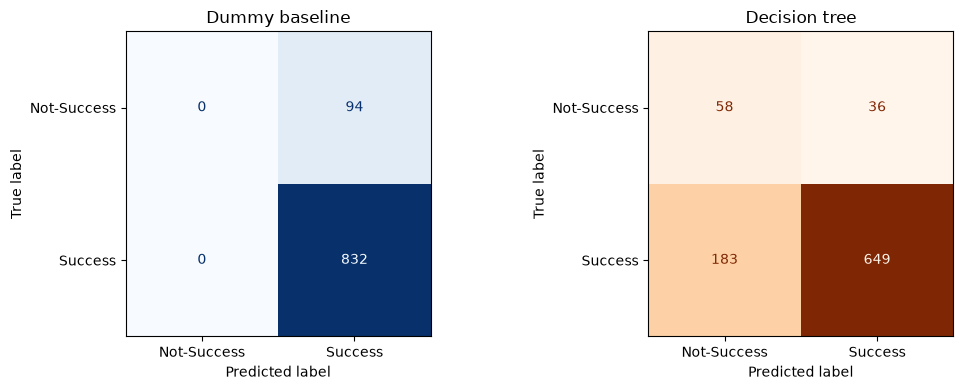

In [9]:
# Confusion matrix for the required simple model.
tree_cm = confusion_matrix(y_test, tree_pred, labels=[0, 1])
print("Decision tree confusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(
    tree_cm,
    index=["Actual Not-Success", "Actual Success"],
    columns=["Predicted Not-Success", "Predicted Success"],
))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, baseline_pred, labels=[0, 1]),
    display_labels=["Not-Success", "Success"],
).plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Dummy baseline")
ConfusionMatrixDisplay(
    tree_cm,
    display_labels=["Not-Success", "Success"],
).plot(ax=axes[1], colorbar=False, cmap="Oranges")
axes[1].set_title("Decision tree")
plt.tight_layout()
plt.show()

In [10]:
# Compact interpretation of the primary comparison.
baseline_f1 = results.loc["DummyClassifier", "not_success_f1"]
tree_f1 = results.loc["DecisionTreeClassifier", "not_success_f1"]
print(f"Primary metric — Not-Success F1")
print(f"  Dummy baseline: {baseline_f1:.4f}")
print(f"  Decision tree : {tree_f1:.4f}")
print(f"  Difference    : {tree_f1 - baseline_f1:+.4f}")

if tree_f1 > baseline_f1:
    print("Conclusion: the simple model improves on the naive baseline for the primary metric.")
else:
    print("Conclusion: the simple model does not improve on the naive baseline for the primary metric.")
print("Accuracy is interpreted alongside F1, not on its own, because Success is the majority class.")

Primary metric — Not-Success F1
  Dummy baseline: 0.0000
  Decision tree : 0.3463
  Difference    : +0.3463
Conclusion: the simple model improves on the naive baseline for the primary metric.
Accuracy is interpreted alongside F1, not on its own, because Success is the majority class.


### Decision-tree feature importance

Feature importance is descriptive, not causal. It indicates which encoded inputs were
used most by this particular tree and should not be interpreted as proof that a feature
causes mission success.

,importance
Company_Prior_Failure_Rate,0.5331
Company_Prior_Launches,0.2318
Rocket_Freq,0.1202
Launch_Year,0.0357
Country_Russia,0.0218
Country_Usa,0.0157
Company_ISA,0.0131
Company_NASA,0.0125
Month_Sin,0.0088
Company_Northrop,0.0051


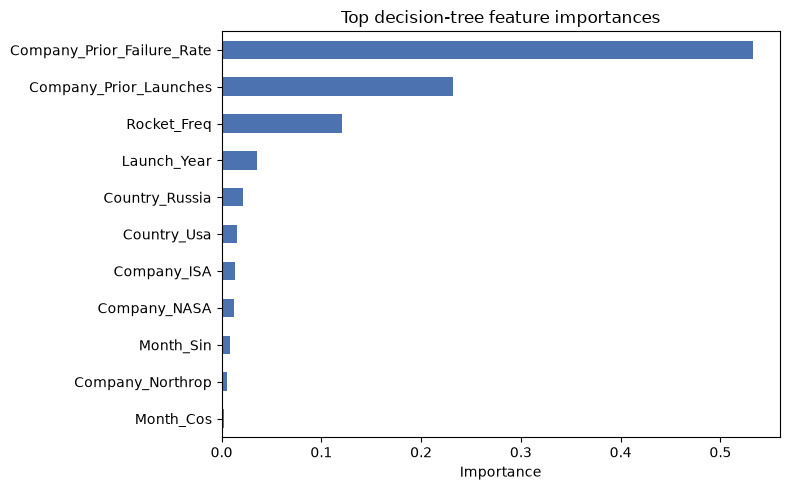

In [11]:
importance = pd.Series(tree_model.feature_importances_, index=feature_names)
top_importance = importance[importance > 0].sort_values(ascending=False).head(15)

display(top_importance.to_frame("importance").style.format("{:.4f}"))

top_importance.sort_values().plot(kind="barh", figsize=(8, 5), color="#4C72B0")
plt.title("Top decision-tree feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Part F — Initial error analysis

The saved Activity 1 matrices do not contain original CSV row IDs. Therefore, the
analysis below identifies test observations by their stable position in `X_test` and
shows the strongest encoded feature values for each misclassified observation. This
is still a valid inspection of individual held-out observations, but a future pipeline
should save source row IDs alongside `X_train` and `X_test` to make the analysis easier
to interpret in the original mission vocabulary.

In [12]:
# Inspect individual misclassified held-out observations.
tree_prob_not_success = tree_model.predict_proba(X_test)[:, 0]
misclassified_mask = tree_pred != y_test
misclassified_positions = np.flatnonzero(misclassified_mask)

error_table = pd.DataFrame({
    "test_row_position": misclassified_positions,
    "actual": [label_names[int(v)] for v in y_test[misclassified_positions]],
    "predicted": [label_names[int(v)] for v in tree_pred[misclassified_positions]],
    "p_Not-Success": tree_prob_not_success[misclassified_positions],
})

# Include the largest-magnitude encoded values to make each inspected row concrete.
def top_feature_summary(row, n=5):
    idx = np.argsort(np.abs(row))[::-1][:n]
    return "; ".join(f"{feature_names[i]}={row[i]:.3f}" for i in idx)

error_table["strongest_encoded_features"] = [
    top_feature_summary(X_test[i]) for i in misclassified_positions
]

# Show at least five errors when available, prioritising errors with the largest
# predicted Not-Success probability so the cases are not arbitrary.
error_table = error_table.sort_values("p_Not-Success", ascending=False)
errors_to_inspect = error_table.head(min(10, len(error_table))).reset_index(drop=True)
errors_to_inspect

,test_row_position,actual,predicted,p_Not-Success,strongest_encoded_features
0,673,Success,Not-Success,0.942242,Launch_Year=1.683; Month_Sin=1.454; Company_Pr...
1,613,Success,Not-Success,0.942242,Month_Sin=-1.202; Company_Prior_Failure_Rate=-...
2,569,Success,Not-Success,0.942242,Month_Cos=1.228; Launch_Year=1.115; Company_Pr...
3,877,Success,Not-Success,0.942242,Month_Sin=-1.392; Launch_Year=1.218; Company_P...
4,834,Success,Not-Success,0.942242,Launch_Year=1.528; Month_Cos=-1.208; Company_P...
5,408,Success,Not-Success,0.909179,Company_Prior_Failure_Rate=2.821; Month_Cos=-1...
6,343,Success,Not-Success,0.909179,Company_Prior_Failure_Rate=2.442; Launch_Year=...
7,148,Success,Not-Success,0.909179,Company_Prior_Failure_Rate=3.374; Launch_Year=...
8,36,Success,Not-Success,0.909179,Company_Prior_Failure_Rate=1.715; Month_Cos=1....
9,102,Success,Not-Success,0.909179,Company_Prior_Failure_Rate=2.682; Launch_Year=...


In [13]:
# Summarise the error pattern by actual/predicted class.
error_pattern = pd.crosstab(
    pd.Series(y_test, name="Actual"),
    pd.Series(tree_pred, name="Predicted"),
).rename(index=label_names, columns=label_names)
error_pattern

Predicted,Not-Success,Success
Actual,,
Not-Success,58,36
Success,183,649


### Error-analysis interpretation

The table distinguishes two kinds of mistakes:

- **False negatives:** actual Not-Success missions predicted as Success. These are the most consequential misses for the stated objective and explain why recall matters.
- **False positives:** actual Success missions predicted as Not-Success. These reduce precision and could create unnecessary failure alerts.

The class-weighted tree intentionally accepts more false positives in exchange for
higher Not-Success recall. The low minority-class precision indicates that many of
its failure alerts are not actual failures. This is useful evidence for the next
modeling step, but it does not justify production use yet.

## Part G — Mini model card

In [14]:
primary_f1 = results.loc["DecisionTreeClassifier", "not_success_f1"]
primary_precision = results.loc["DecisionTreeClassifier", "not_success_precision"]
primary_recall = results.loc["DecisionTreeClassifier", "not_success_recall"]
primary_accuracy = results.loc["DecisionTreeClassifier", "accuracy"]

model_card = pd.DataFrame([
    ["Objective", "Predict Success versus Not-Success for one space mission."],
    ["Data used", f"{len(y_train) + len(y_test):,} missions; {X_train.shape[1]} encoded features; stratified 80/20 split."],
    ["Method", "DummyClassifier majority baseline compared with a class-weighted shallow DecisionTreeClassifier."],
    ["Main result", f"Not-Success F1 = {primary_f1:.4f}; precision = {primary_precision:.4f}; recall = {primary_recall:.4f}; accuracy = {primary_accuracy:.4f}."],
    ["Limitation", "The split is random rather than chronological, the minority class is small, and original row IDs were not retained in the saved arrays."],
    ["Next step", "Evaluate a chronological holdout and test LogisticRegression or a carefully validated ensemble without leakage."],
], columns=["item", "report"])
model_card

,item,report
0,Objective,Predict Success versus Not-Success for one spa...
1,Data used,"4,628 missions; 46 encoded features; stratifie..."
2,Method,DummyClassifier majority baseline compared wit...
3,Main result,Not-Success F1 = 0.3463; precision = 0.2407; r...
4,Limitation,"The split is random rather than chronological,..."
5,Next step,Evaluate a chronological holdout and test Logi...


## Final reflection

1. **Did the first model perform meaningfully better than the baseline?**  
   Yes, on the metric that matters. The dummy baseline cannot identify any failures
   (Not-Success F1 = 0.0000) because it always predicts Success. The tree achieved a
   Not-Success F1 of 0.3463, correctly detecting 58 of 94 test failures. This comparison
   is also a useful safeguard against overfitting-style illusions: the tree was fitted on
   training data only and evaluated once on an untouched test set, so because it still
   beats a zero-knowledge baseline on unseen missions, its improvement reflects genuine
   generalization rather than memorization. We acknowledge the trade-off, though: low
   precision (≈0.24) and lower accuracy (0.7635 vs 0.8985) mean the improvement is real
   but modest.

2. **Which modeling decision had the greatest effect?**  
   The class-weighted objective and the choice to evaluate Not-Success F1 instead of
   accuracy had the greatest effect on the conclusion. They made minority-class
   detection visible rather than allowing the 90% Success class to dominate the result.

3. **What evidence suggests that the model may fail on unseen data?**  
   Four pieces of evidence: (1) the error analysis showed 183 false positives — the
   model's failure signals are noisy; (2) low precision (≈0.24) means most failure
   alerts are wrong; (3) the tree was evaluated on a single random holdout with no
   cross-validation or train-vs-test comparison, so we do not know how stable or
   memorized that score is; and (4) the random split mixes mission eras (1957–2022),
   making the prediction task easier than the real future-prediction setting.

4. **What is the single most important improvement to test next?**  
   A chronological holdout: train on earlier missions and evaluate on later ones. This
   directly simulates the real deployment goal — predicting future launches from past
   data — and tests whether the random split's result was optimistic. It comes before
   trying more complex models, because an optimistic validation would mislead all
   further modeling decisions.


In [15]:
# Final reproducibility summary.
print("Activity 2 baseline notebook completed.")
print(f"Train/test rows: {len(y_train):,} / {len(y_test):,}")
print(f"Primary metric (Not-Success F1): {primary_f1:.4f}")
print(f"Naive baseline F1: {baseline_f1:.4f}")
print(f"Decision tree F1 improvement: {tree_f1 - baseline_f1:+.4f}")

Activity 2 baseline notebook completed.
Train/test rows: 3,702 / 926
Primary metric (Not-Success F1): 0.3463
Naive baseline F1: 0.0000
Decision tree F1 improvement: +0.3463
